In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("RAW_interactions.csv", usecols=["user_id", "recipe_id", "rating"])
recipies =  pd.read_csv("RAW_recipes.csv", usecols=["id", "name", "tags", "ingredients", "n_ingredients"])
raw = df.copy()
print("start:", len(df))

#remove 0, reviews without stars
df = df[df.rating > 0]
print("without rating 0: ", len(df))

#remove duplicates
df = df.drop_duplicates(["user_id", "recipe_id"])
print("without duplicates: ", len(df))


#K-core: users and recipies need atleast 15 ratings
K=15
while True:
    per_user = df.groupby("user_id").recipe_id.transform("size")
    per_recipe = df.groupby("recipe_id").user_id.transform("size")
    keep = (per_user >= K) & (per_recipe >= K)
    if keep.all():
        break
    df= df[keep]
print(f"after removing {K}-core: ", len(df))

df.to_csv("ratings_clean.csv", index=False)


start: 1132367
without rating 0:  1071520
without duplicates:  1071520
after removing 15-core:  179654


raw 1132367 ratings:  226570 users,  231637 recipies, sparsity:  0.9999784237051572
cleaned 179654 ratings:  3807 users,  5433 recipies, sparsity:  0.9913141103137095


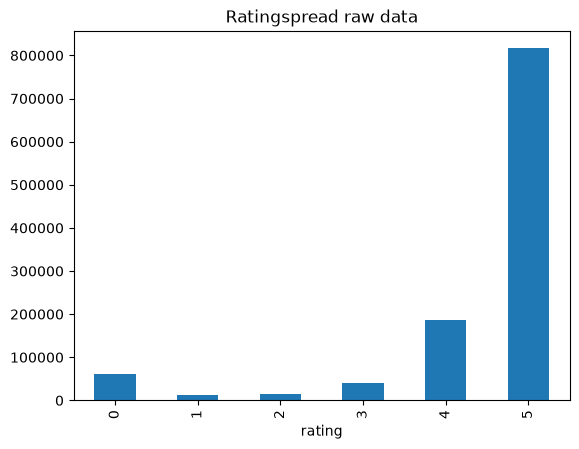

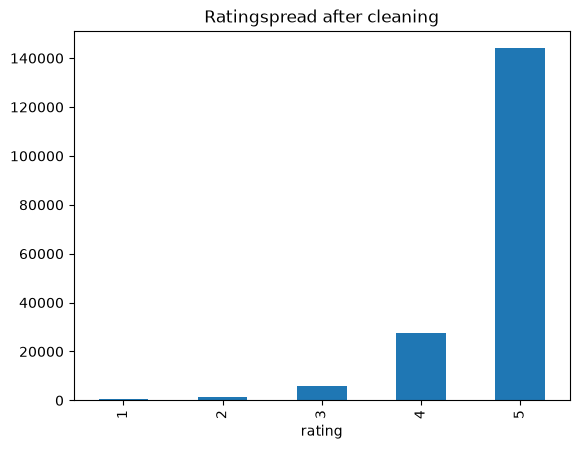

count    3807.000000
mean       47.190439
std        59.075895
min        15.000000
25%        19.000000
50%        28.000000
75%        50.000000
max      1443.000000
dtype: float64
count    5433.000000
mean       33.067182
std        34.219631
min        15.000000
25%        17.000000
50%        22.000000
75%        34.000000
max       566.000000
dtype: float64


recipe_id
27208                           to die for crock pot roast
89204    crock pot chicken with black beans   cream cheese
39087                           creamy cajun chicken pasta
69173     kittencal s italian melt in your mouth meatballs
32204                  whatever floats your boat  brownies
22782                     jo mama s world famous spaghetti
28148                      oven fried chicken chimichangas
68955                               japanese mum s chicken
82102    kittencal s moist cheddar garlic oven fried ch...
77397       kittencal s 5 minute cinnamon flop brunch cake
Name: name, dtype: str


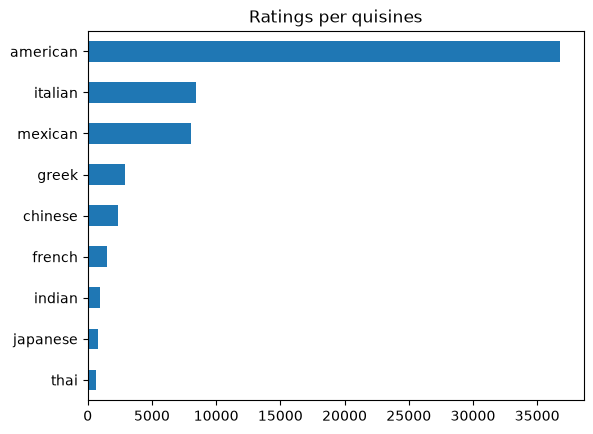

In [2]:
#print(raw.head())
#print(raw.shape)
#print(raw.dtypes)
#print(raw.isna().sum())

def stats(d, name):
    users, items, n = d.user_id.nunique(), d.recipe_id.nunique(), len(d)
    print(name, n, "ratings: ", users, "users, ", items, "recipies, sparsity: ", 1-n / (users * items))

stats(raw, "raw")
stats(df, "cleaned")

#visual of ratings
raw.rating.value_counts().sort_index().plot(kind="bar", title="Ratingspread raw data")
plt.show()
df.rating.value_counts().sort_index().plot(kind="bar", title="Ratingspread after cleaning")
plt.show()

#ratingdata user and recipe
print(df.groupby("user_id").size().describe())
print(df.groupby("recipe_id").size().describe())

print("\n")

#top recipies
top = df.recipe_id.value_counts().head(10)
print(recipies.set_index("id").loc[top.index, "name"])

#ratings per quisine
m = df.merge(recipies, left_on="recipe_id", right_on="id")
cuisines = ["american", "italian", "mexican", "chinese", "indian", "french", "greek", "thai", "japanese"]
counts = {c: m.tags.str.contains(f"'{c}'").sum() for c in cuisines}
pd.Series(counts).sort_values().plot(kind="barh", title="Ratings per quisines")
plt.show()


In [3]:
from surprise import Dataset, Reader, SVD, KNNWithMeans
from surprise.model_selection import train_test_split

#surprise format + 70/30 split
data = Dataset.load_from_df(df[["user_id", "recipe_id", "rating"]], Reader(rating_scale=(1, 5)))
trainset, testset = train_test_split(data, test_size=0.3, random_state=42)

#train the two CF models
knn = KNNWithMeans(k=40, sim_options={"name": "pearson", "user_based": True})
knn.fit(trainset)

svd = SVD(random_state=42)
svd.fit(trainset)

#top 10 recommendations for one user
def recommend(model, user_id, n=10):
    seen = df[df.user_id == user_id].recipe_id
    candidates = df.recipe_id[~df.recipe_id.isin(seen)].unique()
    preds = pd.DataFrame({"id": candidates})
    preds["rating"] = [model.predict(user_id, r, clip=False).est for r in candidates]
    preds = preds.sort_values("rating", ascending=False).head(n)
    return preds.merge(recipies[["id", "name"]], on="id")

user = df.user_id.value_counts().index[100]
print(recommend(svd, user))
print(recommend(knn, user))

ModuleNotFoundError: No module named 'surprise'